# Problem set 6: Optimization - comments/solutions

# Programming for Economists Autumn 2026: Class 3
**Matias BF Hall**

We continue with the consumer problem from Lecture 6. The aim is to formulate the problem carefully, solve it on a grid, and then use numerical optimizers from `scipy.optimize`.

**Table of contents**<a id='toc0_'></a>    
- 1. [CES function](#toc1_)    
- 2. [Value-of-choice](#toc2_)    
- 3. [Grid search](#toc3_)    
- 4. [`scipy.optimize`](#toc4_)    
- 5. [Two choices with SLSQP](#toc5_)    
- 6. [Optional: Price shock](#toc6_)    

<!-- vscode-jupyter-toc-config
	numbering=true
	anchor=true
	flat=false
	minLevel=2
	maxLevel=6
	/vscode-jupyter-toc-config -->
<!-- THIS CELL WILL BE REPLACED ON TOC UPDATE. DO NOT WRITE YOUR TEXT IN THIS CELL -->

In [1]:
import numpy as np
from scipy import optimize

# I use SimpleNamespace to store parameters in a more organized way
from types import SimpleNamespace # a simplenamespace is like a dictionary, but you can access the values with dot notation (e.g. ns.x1 instead of ns['x1'])

## 1. <a id='toc1_'></a>[CES function](#toc0_)

Implement a Python version of this function. With $\beta>0$ the formula takes a negative power of zero when a quantity is zero, which fails. Use an `if` and return `0.0` when either quantity is zero; that is the limit value of CES utility there. Your function then takes one bundle at a time.

$$ 
u(x_1,x_2) = (\alpha x_1^{-\beta} + (1-\alpha) x_2^{-\beta})^{-1/\beta} 
$$

In [2]:
# Utility function for CES preferences
# Defining a function named 'utility_ces' that takes four parameters: x1, x2, alpha, and beta 
def utility_ces(x1,x2,alpha,beta):
    if x1 > 0 and x2 > 0: # avoid division by zero
        return (alpha*x1**(-beta) + (1-alpha)*x2**(-beta))**(-1/beta)
    else:
        return -np.inf  # utility is -inf if any good is zero

## 2. <a id='toc2_'></a>[Value-of-choice](#toc0_)

The consumer faces the following budget constraint:

$$ p_1 x_1 + p_2 x_2 \le I, \quad x_1 \ge 0,\; x_2 \ge 0. $$

**Tasks:** Use your function from above that contains the CES utility function and embed it into another function *value_of_choice_ces* that returns the value of utility *u*. Use only $x_1$ as input into the function and compute $x_2$ within the function,

$$x_2 = (I - p_1x_1)/p_2.$$

Evaluate for some $x_1$ values.

In [3]:
# use these baseline parameters
alpha = 0.5
beta = 0.5
I = 10
p1 = 1
p2 = 2
x1_vec = [0.5,1.0,1.5]

In [4]:
def value_of_choice_ces(x1,alpha,beta,p1,p2,I):
    # Compute x2 from the budget constraint
    x2 = (I - p1*x1)/p2
    # Compute utility using the utility function we made above
    u = utility_ces(x1, x2, alpha, beta)
    return u

Next, we will compare different methods to solve the consumer problem.

## 3. <a id='toc3_'></a>[Grid search](#toc0_)

Set up a grid of the budget set and solve the consumer problem on the grid.

**Idea:** Search over a grid for  $x_1 \in [0, I/p_1]$, and  $x_2 \in [0, I/p_2]$ to find the values of $x_1$ and $x_2$ that maximize utility.


**Task A:** Adapt the 2D grid search from Lecture 6, Section 2 to CES utility. Use `N1 = N2 = 100`, so you try 10,000 pairs, and count the pairs tried. Report the best bundle, its utility and the budget left.

In [5]:
# function for printing the solution
def print_solution(x1,x2,u,I,p1,p2,N):
    if N.ndim == 1:
        print(f'Function evaluations: N = {N.size:_.0f}')
    else:
        print(f'Pairs tried(function evaluations): {N.shape[0]} x {N.shape[1]} = {N.shape[0]*N.shape[1]:_.0f}')
    print(f'x1* = {x1:.6f}')
    print(f'x2* = {x2:.6f}')
    print(f'u  = {u:.6f}')
    print(f'Budget left: I-p1*x1-p2*x2 = {I-p1*x1-p2*x2:.6f}')
    print(f'Expenditure share of good 1: x1*p1/I = {x1*p1/I:.4f}')

In [6]:
# define the grid search function
def find_best_choice(u_func,alpha,beta,I,p1,p2,N1,N2,do_print=True):
    # N1 and N2 are the number of grid points for x1 and x2, respectively
    # we set do_print to True, so the solution is always printed unless set to false when calling the function
    
    # a. allocate numpy arrays
    shape_tuple = (N1,N2) # create a tuple with the shape of the arrays we want to create
    x1_values = np.empty(shape_tuple) # create an empty numpy array with the shape of the tuple
    x2_values = np.empty(shape_tuple)
    u_values = np.empty(shape_tuple)

    # b. start from guess of x1=x2=0, set u_best to not consuming so any u is better
    x1_best = 0
    x2_best = 0
    u_best = u_func(x1_best,x2_best,alpha,beta)
    
    # c. loop through all possibilities
    for i in range(N1):
        for j in range(N2):
            
            # i. x1 and x2 (chained assignment)
            # the chained assignment allows us to assign the same value to both the array and the variable x1/x2.
            # both the array and variable take the value of the expression on the right-hand side.
            x1_values[i,j] = x1 = (i/(N1-1))*I/p1
            x2_values[i,j] = x2 = (j/(N2-1))*I/p2
            # we create a grid of possible (x1,x2) pairs as a fraction of the budget. The grid is created by varying x1 and x2 from 0 to their maximum affordable values given income I and prices p1 and p2.
            # note that this grid includes points that are not affordable, e.g. (I/p1,I/p2)
            # we index by the position of x1 and x2: (i,j)
            # a np.linspace between 0 and I/p1 for x1 and between 0 and I/p2 for x2 would also work.
            
            # ii. utility
            if p1*x1 + p2*x2 <= I: # u(x1,x2) if expenditures <= income
                u_values[i,j] = u_func(x1,x2,alpha=alpha,beta=beta)
            else: # u(0,0) if expenditures > income, not allowed
                u_values[i,j] = u_func(0,0,alpha=alpha,beta=beta)
            # regardless of whether the choice is affordable, we store the utility in the u_values array with the same indexing as x1_values and x2_values.
                            
            # iii. check if best sofar
            if u_values[i,j] > u_best:
                # if the utility at this (x1,x2) pair is greater than the best utility found so far, we update the best values
                x1_best = x1_values[i,j]
                x2_best = x2_values[i,j] 
                u_best = u_values[i,j]
    
    # d. print
    if do_print:
        print_solution(x1_best,x2_best,u_best,I,p1,p2,N=np.zeros((N1,N2)))

    # e. return - we return a SimpleNamespace object containing the best values and the arrays of all values to access later.
    return SimpleNamespace(x1_best=x1_best,x2_best=x2_best,u_best=u_best,x1_values=x1_values,x2_values=x2_values,u_values=u_values)

In [7]:
# choose the number of grid points for x1 and x2
N1 = 100
N2 = 100

# solve using function
sol_grid = find_best_choice(utility_ces, alpha, beta, I, p1, p2, N1, N2, do_print=True)

Pairs tried(function evaluations): 100 x 100 = 10_000
x1* = 4.444444
x2* = 2.777778
u  = 3.465574
Budget left: I-p1*x1-p2*x2 = 0.000000
Expenditure share of good 1: x1*p1/I = 0.4444


**Search the budget line.** CES utility is strictly increasing in both goods, so the optimum spends the whole budget. This turns the 2D search into a **1D search**: choose a grid for $x_1 \in [0, I/p_1]$ and set $x_2 = (I-p_1 x_1)/p_2$.

**Task B:** Adapt the budget-line grid from Lecture 6, Section 3 to CES utility. Use `N = 10000` points, the same number of tries as the $100\times100$ grid. Because your CES function uses `if`, it takes one bundle at a time: loop over the grid points to fill a utility array, then use `np.argmax`. Which search is more accurate for the same effort?

In [8]:
# less comments because it is similar to above. See above for more detailed comments.

# we modify the code from lecture 6
# we add the input: beta
def find_best_choice_monotone(u_func,alpha,beta,I,p1,p2,N,do_print=True):
    
    # a. allocate numpy arrays
    shape_tuple = (N) # the tuple is now just one-dimensional
    x1_values = np.empty(shape_tuple)
    x2_values = np.empty(shape_tuple)
    u_values = np.empty(shape_tuple)
    
    # b. start from guess of x1=x2=0
    x1_best = 0
    x2_best = 0
    u_best = u_func(x1_best,x2_best,alpha,beta) # added beta
    
    # c. loop through all possibilities
    for i in range(N):
        
        # i. x1
        x1_values[i] = x1 = i/(N-1)*I/p1 # x1 is still a fraction of the budget
        
        # ii. implied x2 by budget constraint
        x2_values[i] = x2 = (I-p1*x1)/p2 # x2 is whatever is left of the budget after spending on x1
            
        # iii. utility    
        u_values[i] = u_func(x1,x2,alpha,beta) # added beta

        # iiii. check and update best so far
        if u_values[i] >= u_best:    
            x1_best = x1_values[i]
            x2_best = x2_values[i] 
            u_best = u_values[i]

    # d. alternative find best u using argmax instead
    best_index = np.argmax(u_values) # find the index of the maximum utility in the u_values array
    # use the index to find the corresponding x1, x2, and u values
    x1_best_argmax = x1_values[best_index]
    x2_best_argmax = x2_values[best_index]
    u_best_argmax = u_values[best_index]

    # e. print
    if do_print:
        print('Solution using loop:')
        print_solution(x1_best,x2_best,u_best,I,p1,p2,N=np.zeros((N,))) # we pass a 1D array of zeros to the print function to indicate the number of function evaluations
        print('\nAlternative solution using argmax:')
        print_solution(x1_best_argmax,x2_best_argmax,u_best_argmax,I,p1,p2,N=np.zeros((N,)))
    return SimpleNamespace(x1_best=x1_best,x2_best=x2_best,u_best=u_best,x1_values=x1_values,x2_values=x2_values,u_values=u_values),SimpleNamespace(x1_best=x1_best_argmax,x2_best=x2_best_argmax,u_best=u_best_argmax,x1_values=x1_values,x2_values=x2_values,u_values=u_values)

In [9]:
# set number of grid points for x1 and x2
N = 10_000 # use '_' as a thousands separator for readability

sol_monotone, sol_monotone_argmax = find_best_choice_monotone(utility_ces, alpha, beta, I, p1, p2, N, do_print=True)

Solution using loop:
Function evaluations: N = 10_000
x1* = 4.424442
x2* = 2.787779
u  = 3.465614
Budget left: I-p1*x1-p2*x2 = 0.000000
Expenditure share of good 1: x1*p1/I = 0.4424

Alternative solution using argmax:
Function evaluations: N = 10_000
x1* = 4.424442
x2* = 2.787779
u  = 3.465614
Budget left: I-p1*x1-p2*x2 = 0.000000
Expenditure share of good 1: x1*p1/I = 0.4424


**Most accurate search?**  
Both searches are approximately equally fast, but the 1D search is more accurate because it searches the budget line. The 1D search has the same amount of points, but since all points are feasible, unlike the 2D search, it is more accurate. 1D searches are more accurate in general, given you limit the search space. When you combine methods such as interpolation, a numerical optimizer and a less straightforward function to optimise, the 1D search will also be faster.

## 4. <a id='toc4_'></a>[`scipy.optimize`](#toc0_)

**Task:** Solve the consumer problem using `scipy.optimize.minimize_scalar`, as in Lecture 6, Section 4.

1. Define an objective function that returns minus utility along the budget line.
2. Pass the parameters with `args` and use `method='bounded'` with bounds $0 \leq x_1 \leq I/p_1$.
3. Check `.success`, then print the optimal bundle and compare it with the grid-search solutions.
4. How many function evaluations (`.nfev`) did the solver need, compared with the 10,000 tries of each grid?

In [10]:
# since it is a minimizer we set the objective function as the negative of the value of choice function defined above
obj = lambda x1: -value_of_choice_ces(x1,alpha,beta,p1,p2,I)

# define bounds and run the solver
# we know that x1 must be between 0 and I/p1 (spending all income on good 1)
# if we did not know the solution we could chose these bounds as a general feasible set
# since we know the approximate solution we can tighten the bounds to speed up the process

bounds = (4.0,5.0) # This would be a good guess. Without information about the solution I would guess (1e-10, I/p1)
#bounds = (1e-10,I/p1)
sol_minimize = optimize.minimize_scalar(obj,bounds=bounds)
# since I defined the objective function as only taking one argument, all the other parameters are passed in through the lambda function from the global scope.
# alternatively we could write the objective function as a function of x1 and pass the other parameters as args to the minimize_scalar function, but I prefer this way because it is more readable.
obj_withargs = lambda x1,alpha,beta,p1,p2,I: -value_of_choice_ces(x1,alpha,beta,p1,p2,I)
sol_minimize_withargs = optimize.minimize_scalar(obj_withargs, args=(alpha, beta, p1, p2, I), bounds=bounds) # we need to explicitly tell optimize.minimize_scalar that the other parameters should be passed in with the global scope, otherwise it will not know what they are.

# get results out of solution object and print
u_ces = -sol_minimize.fun # get the function value at the solution and negate it to get the utility
x1_ces = sol_minimize.x # get the optimal x1
x2_ces = (I-x1_ces*p1)/p2 # compute optimal x2 from budget constraint
print(f'Solution found? {sol_minimize.success}') # check if the solver found a solution
print(f'x1* = {x1_ces:.6f}, x2* = {x2_ces:.6f}, u* = {u_ces:.6f}') # print
print(f'With args: x1* = {sol_minimize_withargs.x:.6f}, x2* = {(I-sol_minimize_withargs.x*p1)/p2:.6f}, u* = {-sol_minimize_withargs.fun:.6f}') # print with args
print(f'The optimiser used {sol_minimize.nfev} function evaluations which is {sol_minimize.nfev/N:.4f} of the grid search') # print number of function evaluations and compare to grid search


Solution found? True
x1* = 4.424934, x2* = 2.787533, u* = 3.465614
With args: x1* = 4.424934, x2* = 2.787533, u* = 3.465614
The optimiser used 8 function evaluations which is 0.0008 of the grid search


## 5. <a id='toc5_'></a>[Two choices with SLSQP](#toc0_)

**Task:** Now let the solver choose **both** quantities with `optimize.minimize` and `method='SLSQP'`, as in Lecture 6, Section 5. Give it bounds for each quantity and the budget as an inequality dictionary.

1. Compare the bundle and the number of function evaluations with `minimize_scalar`.
2. Solve again from three different affordable starting bundles. Do all starts end at the same bundle?

In [11]:
# The difference here from Q6 is that we now have to use scipy.minimize to specify the methods
# The syntax is slightly different, but the idea is the same
# In the minimize method we need to specify a starting value
# We also need to have the objective function choose elements,
# as minimize expects a function that takes an array-like input
# We also use the time package to time how long the optimization takes
# lastly a starting guess is required for the optimization
# In the print "nit" = number of iterations, "nfev" = number of function evaluations

# Import time package
import time # usually we want to import all packages at the top of the file

# set initial guess
# E.g. one possibility is that half of income is spent on good 1 and the other half on good 2
# Any value between (close to)zero and all of income is good
# I opted for no bounds as bounds are not required parameters for SLSQP, and the function is well behaved
# Further away from the solution will likely take longer to converge
# Lets start at values close to zero for this example
x0 = [1e-8,1e-8] # we need to pass an array-like input to the objective function. The first element is the initial guess for x1 and the second element is the initial guess for x2.
# lets also define three different starting guesses to see if the solution is robust to different starting values for question 2
x0s = [[1e-8,1e-8],[I/p1/2,I/p2/2],[I/p1,I/p2]]


##### No Constraints #####
# define objective function for minimize
obj = lambda x: -utility_ces(x[0], x[1], alpha, beta) # we want to optimise negative utility since we are using a minimizer. The input x is an array-like object where x[0] is x1 and x[1] is x2.

# create variable holding time at start of optimization
t0 = time.perf_counter()

# run the optimiser
res_slsqp = optimize.minimize(obj, x0=x0, method="SLSQP")

# create variable holding time at end of optimization
t1 = time.perf_counter()

# extract results
x1_slsqp = res_slsqp.x[0]
x2_slsqp = res_slsqp.x[1]

# save solution in a SimpleNamespace object as with all other solutions
sol_slsqp = SimpleNamespace(x1_best=x1_slsqp, x2_best=x2_slsqp, u_best=utility_ces(x1_slsqp, x2_slsqp, alpha, beta), iterations=res_slsqp.nit, function_evaluations=res_slsqp.nfev, time_ms=(t1-t0)*1e3)

# check if solution is found
print(f'Solution found? {res_slsqp.success}')

##### Q1 #####
# repeat using bounds and the budget constraint as a constraint

# define the budget constraint as a function and write it as a dictionary to pass to the minimize function.
net_budget = lambda x: I - p1*x[0] - p2*x[1] # the budget constraint is that income minus expenditures must be non-negative
budget_constraint = {'type': 'ineq', 'fun': net_budget} # the budget constraint is an inequality constraint, so we set the type to 'ineq'. Since I,p1,p2 are defined in the global scope, we can use them in the lambda function without passing them as arguments.

# set bounds between 0 and I/p1 for x1 and between 0 and I/p2 for x2.
bounds = [(1e-8, I/p1), (1e-8, I/p2)] 

# solve
t0 = time.perf_counter()
res_slsqp_bound = optimize.minimize(obj, x0=x0, method="SLSQP", bounds=bounds, constraints=budget_constraint)
t1 = time.perf_counter()

# extract and save results
x1_slsqp_bound = res_slsqp_bound.x[0]
x2_slsqp_bound = res_slsqp_bound.x[1]

# compute time by subtracting t0 from t1
# nit and nfev are attributes of the result object returned by minimize
sol_slsqp_bound = SimpleNamespace(x1_best=x1_slsqp_bound, x2_best=x2_slsqp_bound, u_best=utility_ces(x1_slsqp_bound, x2_slsqp_bound, alpha, beta), iterations=res_slsqp_bound.nit, function_evaluations=res_slsqp_bound.nfev, time_ms=(t1-t0)*1e3)


##### Monotonicity #####
# let's try using only x1 as the variable and computing x2 from the budget constraint
# define objective function for minimize using only x1 as the variable and computing x2 from the budget constraint
def obj_onepar(x):
    # As we only optimise over x1, we extract it from the array-like input x with index 0
    x1 = x[0]
    x2 = (I - p1*x1)/p2
    return -utility_ces(x1, x2, alpha, beta)

# solve
t0 = time.perf_counter()
res_slsqp_onepar = optimize.minimize(obj_onepar, x0=x0, method="SLSQP")
t1 = time.perf_counter()

# extract results and save
x1_slsqp_onepar = res_slsqp_onepar.x[0]
x2_slsqp_onepar = (I-x1_slsqp_onepar*p1)/p2 # compute x2 from x1 using budget constraint

sol_slsqp_onepar = SimpleNamespace(x1_best=x1_slsqp_onepar, x2_best=x2_slsqp_onepar, u_best=utility_ces(x1_slsqp_onepar, x2_slsqp_onepar, alpha, beta), iterations=res_slsqp_onepar.nit, function_evaluations=res_slsqp_onepar.nfev, time_ms=(t1-t0)*1e3)

# compare the results of the different methods, all using the same starting guess and the same parameters. The results should be the same, but the number of iterations, function evaluations and computing time may differ.
# create a print function
def print_namespace(ns):
    print(f'x1*={ns.x1_best:.10f}, x2*={ns.x2_best:.10f}, u*={ns.u_best:.10f}, iterations={ns.iterations}, function evaluations={ns.function_evaluations}, time={ns.time_ms:.1f} ms')
# print
print('\nComparison of SLSQP with different approaches:\n')
print('No bounds or constraints:')
print_namespace(sol_slsqp)
print('\nWith bounds and budget constraint:')
print_namespace(sol_slsqp_bound)
print('\nUsing only x1 as variable and computing x2 from budget constraint:')
print_namespace(sol_slsqp_onepar)

##### Q2 #####

# create empty list to store results
res_slsqp_guesses = []
# loop through the different starting guesses and solve
for x0 in x0s:
    t0 = time.perf_counter()
    res_slsqp_guess = optimize.minimize(obj, x0=x0, method="SLSQP", bounds=bounds, constraints=budget_constraint)
    t1 = time.perf_counter()
    # extract results and save
    x1_slsqp_guess = res_slsqp_guess.x[0]
    x2_slsqp_guess = res_slsqp_guess.x[1]
    sol_slsqp_guess = SimpleNamespace(x1_best=x1_slsqp_guess, x2_best=x2_slsqp_guess, u_best=utility_ces(x1_slsqp_guess, x2_slsqp_guess, alpha, beta), iterations=res_slsqp_guess.nit, function_evaluations=res_slsqp_guess.nfev, time_ms=(t1-t0)*1e3)
    res_slsqp_guesses.append(sol_slsqp_guess)

# print and compare results for different starting guesses
print('\n\nComparison of SLSQP with different starting guesses:\n')
for i, sol in enumerate(res_slsqp_guesses):
    print(f'Starting guess {i+1}: x0={x0s[i]}')
    print_namespace(sol)
    print()

Solution found? False

Comparison of SLSQP with different approaches:

No bounds or constraints:
x1*=2483528160925833.0000000000, x2*=2483528232779667.5000000000, u*=2483528196852749.5000000000, iterations=25, function evaluations=75, time=42.5 ms

With bounds and budget constraint:
x1*=4.4235875236, x2*=2.7882062382, u*=3.4656138078, iterations=7, function evaluations=21, time=3.6 ms

Using only x1 as variable and computing x2 from budget constraint:
x1*=4.4247327909, x2*=2.7876336046, u*=3.4656139944, iterations=5, function evaluations=15, time=1.3 ms


Comparison of SLSQP with different starting guesses:

Starting guess 1: x0=[1e-08, 1e-08]
x1*=4.4235875236, x2*=2.7882062382, u*=3.4656138078, iterations=7, function evaluations=21, time=2.8 ms

Starting guess 2: x0=[5.0, 2.5]
x1*=4.4228480573, x2*=2.7885759714, u*=3.4656135404, iterations=4, function evaluations=12, time=1.8 ms

Starting guess 3: x0=[10.0, 5.0]
x1*=4.4254685688, x2*=2.7872657156, u*=3.4656139684, iterations=6, functi

***Comments:***

1. It is important to bound the search space for the solver, if the problem is bounded. Otherwise, the solver may search in infeasible regions and fail to find the optimum. In the case above, there is no solution to the unconstrained problem, because the utility function is strictly increasing in both goods. Hence, the optimiser will try to increase both goods without limit, and the solver will fail to find a solution. The bounds and the budget constraint are necessary to make the problem bounded.
2. Reducing the dimensionality of the problem is often a good idea as it reduces computing time on all parameters. In this case, we can reduce the problem to one dimension by searching along the budget line. With only one variable the algorithm can guess faster and more accurate. Implicitly bounding/constraining the problem also eliminates the need for the algorithm to adjust its guess every time it goes out of bounds. In this case the 1D search is about 2 times faster than the 2D search, and it is more accurate. When it takes miliseconds to evaluate the function, the difference in speed is not important, but when it takes minutes or hours to evaluate the function, the difference in speed can be very important.
3. The choice of the initial guess can significantly affect the convergence of the solver. A good initial guess can lead to faster convergence and a more accurate solution. All three guesses lead to almost the same solution, but with different compute times. Guess 2 is the fastest because it is closest to the optimum. Guess 1 takes the longest because it starts on a very steep part of the utility function, and the solver has to take many small steps to reach the optimum. Guess 3 is in between in terms of time, but actually finds the best solution of all three initial guesses.
4. Gradient-based methods like SLSQP stop searching when the gradient is close to zero. If the initial guess is in a flat region of the utility function, the solver may stop searching before it reaches the optimum. This is why it is important to choose a good initial guess. We can control when the solver stops searching by setting the `tol` parameter. A smaller `tol` means the solver will search longer and more accurately, but it will take longer to compute. A larger `tol` means the solver will stop searching sooner, but it may not find the optimum. If you set `tol` too small for the solver to converge, you can set the `options={'maxiter': X}` parameter to allow the solver to take more steps. In this case the solver is only accurate to 2 decimals with all three guesses.

## 6. <a id='toc6_'></a>[Optional: Price shock](#toc0_)

**Goal.** Study how the optimal bundle and the consumer's welfare react when the price of good 1 doubles, $p_1 \rightarrow 2p_1$, and how the response depends on the CES curvature parameter $\beta$.

The elasticity of substitution is $1/(1+\beta)$:
- a smaller $\beta$ means that the goods are easier to substitute;
- a larger $\beta$ means that the goods are more complementary.

See **Problem Set 5** for an illustration of the indifference curves.

**Task:**
- For each $\beta \in \{0.1, 0.3, 0.5, 0.7, 0.9\}$, compute the optimum $(x_1^\star, x_2^\star, u^\star)$ at the baseline prices and after $p_1$ doubles.
- For each $\beta$, report the percentage change relative to the baseline.
- Plot two panels: Panel A with the quantity responses, and Panel B with the welfare response.

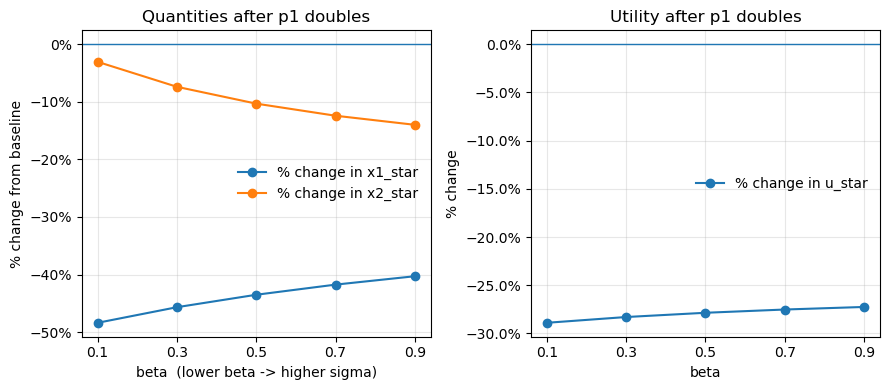

In [12]:
# I recommend you use a numerical solver instead of the analytical solution below, as it is more general and can be used for other models.
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter # again, import at the beginning of the file. I put it here to show where it is used.

betas    = np.array([0.1, 0.3, 0.5, 0.7, 0.9])  # five beta values in (0,1)

# ----- helpers -----
def sigma_from_beta(beta):
    # elasticity of substitution
    return 1.0 / (1.0 + beta)

# analytical solution.
def ces_demands(I, p1, p2, alpha, beta):
    """
    Returns (x1_star, x2_star, u_star, s1, s2) using CES duality.

    Indirect utility: u_star = I / C(p),
    where C(p) = [ alpha^sigma * p1^(1 - sigma) + (1 - alpha)^sigma * p2^(1 - sigma) ]^(1 / (1 - sigma))

    Budget shares:
      s1 = alpha^sigma * p1^(1 - sigma) / denom
      s2 = 1 - s1
    """
    sigma = sigma_from_beta(beta)
    denom = (alpha**sigma) * (p1**(1.0 - sigma)) + ((1.0 - alpha)**sigma) * (p2**(1.0 - sigma))
    s1 = (alpha**sigma) * (p1**(1.0 - sigma)) / denom
    s2 = 1.0 - s1
    x1 = (I / p1) * s1
    x2 = (I / p2) * s2
    C  = denom**(1.0 / (1.0 - sigma))
    u  = I / C
    return x1, x2, u, s1, s2

# ----- baseline vs. shock (p1 doubles) -----
# list comprehensions
# simply put it is a for loop inside the list creation
# so it goes through each beta and computes the solutions
# we transpose the arrays (.T) to access by variable instead of for each beta
base = np.array([ces_demands(I, p1, p2, alpha, b) for b in betas]).T
shck = np.array([ces_demands(I, 2.0*p1, p2, alpha, b) for b in betas]).T

# save the baseline and shock solutions for each variable
x1_b, x2_b, u_b = base[0], base[1], base[2]
x1_s, x2_s, u_s = shck[0], shck[1], shck[2]

# create function to compute percentage change
pct = lambda new, old: 100.0 * (new - old) / old
# use said function
d_x1 = pct(x1_s, x1_b)
d_x2 = pct(x2_s, x2_b)
d_u  = pct(u_s,  u_b)

# ----- plots -----

# plots
# So far you have learned to creat each axis by itself with add_subplot
# With subplots it puts the axis objects in a list that can be accessed by normal indexing
# the '1,2' means 1 row and 2 columns
fig, axs = plt.subplots(1, 2, figsize=(9, 4), sharex=True)


# cosmetic choices, read through and take inspiration for when you need to plot in the future.
# not exactly as the lecture, but close enough - it is possible to spend a lot of time on cosmetics, but I will not do that here.
# Panel A: quantities
axs[0].plot(betas, d_x1, marker='o', label='% change in x1_star')
axs[0].plot(betas, d_x2, marker='o', label='% change in x2_star')
axs[0].set_title('Quantities after p1 doubles')
axs[0].set_xlabel('beta  (lower beta -> higher sigma)')
axs[0].set_ylabel('% change from baseline')
axs[0].axhline(0, linewidth=1)
axs[0].yaxis.set_major_formatter(PercentFormatter())
axs[0].set_xticks(betas.tolist())
axs[0].grid(True, alpha=0.3)
axs[0].legend(frameon=False)

# Panel B: utility
axs[1].plot(betas, d_u, marker='o', label='% change in u_star')
axs[1].set_title('Utility after p1 doubles')
axs[1].set_xlabel('beta')
axs[1].set_ylabel('% change')
axs[1].axhline(0, linewidth=1)
axs[1].yaxis.set_major_formatter(PercentFormatter())
axs[1].set_xticks(betas.tolist())
axs[1].grid(True, alpha=0.3)
axs[1].legend(frameon=False)


plt.tight_layout()
plt.show()


# Conclussion
# The easier it is to substitute one good for another, the more the consumer will do so
# That is high elasticity of substitution -> only income effect on x2 makes the consumer, consume less

**Interpretation:**

- **Good 1.** $x_1^\star$ falls after its price rises. The fall is larger when $\beta$ is small because the consumer can substitute more easily toward good 2.

- **Good 2.** $x_2^\star$ also falls for these parameter values. A substitution effect pushes demand toward good 2, while the fall in real income pushes demand down. Here, the income effect is stronger. The decline is smaller when substitution is easier.

- **Welfare.** $u^\star$ falls for every value of $\beta$. In this example, the quantity responses vary more across $\beta$ than the welfare response.